In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math


In [3]:
def f_normal(x):
  return 2*np.exp(-(x**2)/2)/np.sqrt(2*np.pi)

def g_normal(x):
  return np.exp(-x)

def normal(mi, sigma, seed):
  c = 2*np.exp(1/2)/np.sqrt(2*np.pi)
  valor = None
  while valor == None:
    np.random.seed(seed)
    seed += 1
    u = np.random.uniform()
    y = (-1) * np.log(np.random.uniform())

    if(u < f_normal(y)/(c*g_normal(y))):
      valor = y

  if(np.random.uniform() < 0.5):
    valor = -valor

  if(mi != 0 or sigma != 1):
    valor = (valor * sigma) + mi

  return valor


Item (a)

In [ ]:
def simulacao(x, y, M, seed):
    delta_t = 0.01
    resultados = [] # Lista de 1 e 0 baseado no final
    x_vetor = [] # Lista com a lista das posições de x 
    y_vetor = [] # Lista com a lista das posições de y
    for i in range(M):
        x_i = [x] # Lista das posições de x, começando na posição inicial x recebida pela função
        y_i = [y] # Lista das posições de y, começando na posição inicial y recebida pela função
        x0 = x 
        y0 = y
        while x0**2 + y0**2 < 1: # Condição do loop
            z1 = delta_t**0.5 * normal(0, 1, seed)
            z2 = delta_t**0.5 * normal(0, 1, seed+10_000)
            seed += 1 # Alterando o valor da seed para não gerar o mesmo valor repetidas vezes

            x0 += z1
            y0 += z2
            if((x0)**2 + (y0)**2 > 1):
                norma = (x0**2 + y0**2)**0.5 # Normalizando o vetor, assim x² + y² = 1
                x0 = x0/norma
                y0 = y0/norma

                x_i.append(x0)
                y_i.append(y0)

            else:
                x_i.append(x0)
                y_i.append(y0)
                
        if(x0 > 0):
            resultados.append(1)
        else:
            resultados.append(0)
        x_vetor.append(x_i) # Adicionando a lista de posições ao fim do ciclo
        y_vetor.append(y_i)
    return [np.mean(resultados), x_vetor, y_vetor] #Retorna uma lista com a temperatura estimada, e as listas de posições


In [5]:
delta_t = 0.01
valor_1 = simulacao(0, 0, 1_000, 10)[0]
valor_2 = simulacao(0.3, 0, 1_000, 10)[0]
valor_3 = simulacao(0.7, 0, 1_000, 10)[0]

print(f"Para (0,0), Valor obtido: {valor_1}")
print(f"Para (0.3,0), Valor obtido: {valor_2}")
print(f"Para (0.7,0), Valor obtido: {valor_3}")

Para (0,0), Valor obtido: 0.519
Para (0.3,0), Valor obtido: 0.691
Para (0.7,0), Valor obtido: 0.863


Item (b)

Item (c)

In [6]:
print(f"Para (0,0), Valor obtido: {valor_1}, valor teorico: 0.5, diferença {valor_1 - 0.5}")
print(f"Para (0.3,0), Valor obtido: {valor_2}, valor teorico: 0.686, diferença {valor_2 - 0.686}")
print(f"Para (0.7,0), Valor obtido: {valor_3}, valor teorico: 0.889, diferença {valor_3 - 0.889}")

Para (0,0), Valor obtido: 0.519, valor teorico: 0.5, diferença 0.019000000000000017
Para (0.3,0), Valor obtido: 0.691, valor teorico: 0.686, diferença 0.004999999999999893
Para (0.7,0), Valor obtido: 0.863, valor teorico: 0.889, diferença -0.026000000000000023


Item (d)

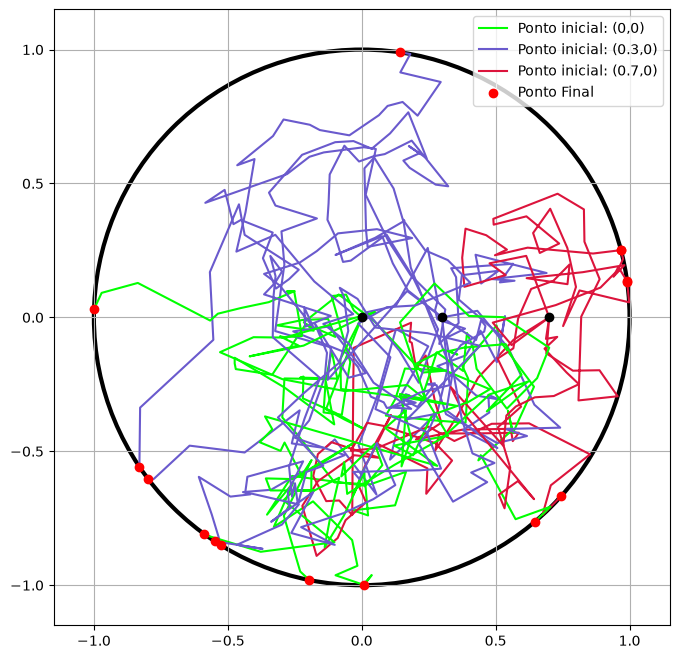

In [ ]:
u1 = simulacao(0, 0, 5, 500) # Posição (0,0)
u2 = simulacao(0.3, 0, 5, 100) # Posição (0.3, 0)
u3 = simulacao(0.7, 0, 5, 1_000) # Posição (0.7, 0)

plt.figure(figsize=(8,8)) # Tamanho da imagem

pontos_x = [] # Lista para armazenar a última posição de x em cada M
pontos_y = [] # Lista para armazenar a última posição de y em cada M

for i in range(len(u1[1])):
    pontos_x.append(u1[1][i][-1])

    pontos_x.append(u2[1][i][-1])

    pontos_x.append(u3[1][i][-1])

    pontos_y.append(u1[2][i][-1])
    
    pontos_y.append(u2[2][i][-1])

    pontos_y.append(u3[2][i][-1])

    label_1 = "Ponto inicial: (0,0)" if(i == 0) else "" # Código para evitar que a legenda repita (Usando o equivalente ao Condição? True : False do javascript)
    label_2 = "Ponto inicial: (0.3,0)" if(i == 0) else ""
    label_3 = "Ponto inicial: (0.7,0)" if(i == 0) else ""

    plt.plot(u1[1][i], u1[2][i], color="lime", label=label_1)
    plt.plot(u2[1][i], u2[2][i], color="slateblue", label=label_2)
    plt.plot(u3[1][i], u3[2][i], color="crimson", label=label_3)

plt.scatter([0, 0.3, 0.7], [0, 0, 0], color="black", zorder=10) # Colocando pontos pretos nas posições iniciais
plt.scatter(pontos_x, pontos_y, color="red", label="Ponto Final", zorder=10) # Colocando pontos vermelhos nas posições finais

plt.xlim(-1.15, 1.15)
plt.ylim(-1.15, 1.15)

plt.gca().add_patch(plt.Circle((0,0), radius=1, color="black", fill=False, linewidth=3)) # Circulo preto de raio 1 para representar a chapa

plt.legend()

plt.grid(True)
plt.show()

Item (e)

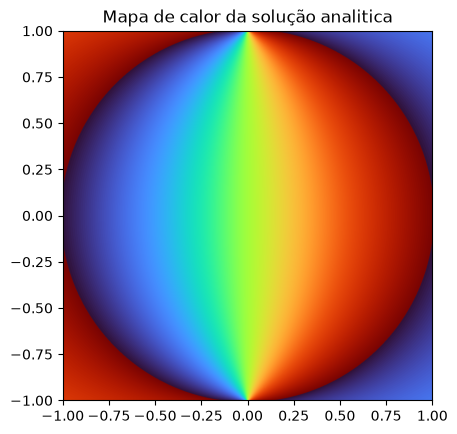

In [ ]:
x = np.linspace(-0.99, 0.99, 1_000)
y = np.linspace(-0.99, 0.99, 1_000)

X, Y = np.meshgrid(x,y) # Transforma o valores em matrizes de mesma dimensão, o imshow trabalha com matrizes. nesse formato X é indexado por X[i, j] igual uma matriz

# Coordenadas Polares:
# r² = x² + y²
# x = r cos(o)

Z = 1/2 + 1/np.pi * np.arctan((2*X/(1 - (X**2 + Y**2)))) # FALTA ARRUMAR PARA FILTRAR X² + Y² <= 1 !!!

plt.imshow(
    Z, 
    cmap="turbo", # Paleta de cor
    origin="lower",
    extent=[-1, 1, -1, 1]
)
plt.title("Mapa de calor da solução analitica")
plt.show()